In this final notebook, we will have a look at the integrability of ML using the NTN channel models. To do that, we will reuse the implementation of the neural receiver of the Sionna tutorial "Neural Receiver for OFDM SIMO Systems" (https://nvlabs.github.io/sionna/phy/tutorials/Neural_Receiver.html), in PyTorch.

The used papers are the paper on a NN based SIMO receiver
DeepRx: Fully convolutional deep learning receiver, submitted to IEEE Transactions on Wireless Communications. arXiv preprint:1711.05101, 2020.
This has already been implemented in the Sionna tutorial above.
The extension for the MIMO case is in the paper:
Korpi, D., Honkala, M., Huttunen, J.M., & Starck, V. (2020). DeepRx MIMO: Convolutional MIMO Detection with Learned Multiplicative Transformations. ICC 2021 - IEEE International Conference on Communications, 1-7.

As the previous examples have shown, the NTN channels are very challenging, especially without perfect CSI. Thus, ML based solutions are a promising solution. The training and the evaluation below simulate the channel without the Doppler shift of the satellite (`doppler_enabled=False`). Additionally, despite this notebook reusing an existing NN already implemented in Sionna, this actually only affects a small part of the code and could be done with any existing NN in PyTorch.

The first code cell sets the device, the precision, the seed and the mode, from the environment variable `OPENNTN_NOTEBOOK_MODE`: unset, the notebook does not train and loads the results of the full run from the file `ML_based_SIMO_receiver_results.npz`; `full`, it trains the receiver with the parameters of this notebook, writes its weights to `ML_based_SIMO_receiver_weights.npz`, evaluates it and writes the results (this needs a GPU: the training takes days on a laptop CPU); `reduced`, it trains for 2 iterations and evaluates 2 points with small batches, with which the continuous integration of OpenNTN runs the notebook, and writes no file.

In [1]:
#
# SPDX-FileCopyrightText: Copyright (c) 2021-2026 NVIDIA CORPORATION & AFFILIATES. All rights reserved.
# SPDX-License-Identifier: Apache-2.0
#
# Modified by the Dept. of Communications Engineering of the University of Bremen.
# The code is based on implementations provided by the NVIDIA CORPORATION & AFFILIATES
# in Sionna.
#

import datetime
import importlib.metadata
import math
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

import sionna
import sionna.phy
from sionna.phy import Block
from sionna.phy.channel import OFDMChannel
from sionna.phy.fec.ldpc import LDPC5GDecoder, LDPC5GEncoder
from sionna.phy.mapping import BinarySource, Demapper, Mapper
from sionna.phy.mimo import StreamManagement
from sionna.phy.ofdm import (LMMSEEqualizer, LSChannelEstimator, RemoveNulledSubcarriers,
                             ResourceGrid, ResourceGridDemapper, ResourceGridMapper)
from sionna.phy.utils import ebnodb2no, expand_to_rank, insert_dims, sim_ber

import openntn
from openntn import AntennaArray, DenseUrban, SubUrban, Urban
from openntn.utils import gen_single_sector_topology as gen_ntn_topology

# The device of the models, the antennas and the receiver: a GPU if one is visible,
# otherwise the CPU
device = sionna.phy.config.device
# Single precision, and a fixed seed, so that every run gives the same results
sionna.phy.config.precision = "single"
seed = 42
sionna.phy.config.seed = seed

# The mode: unset, the results of the full run are loaded from the results file; "full",
# the receiver is trained and evaluated, and its weights and the results are written;
# "reduced", the receiver is trained for 2 iterations and evaluated at 2 points
mode = os.environ.get("OPENNTN_NOTEBOOK_MODE")
if mode not in (None, "full", "reduced"):
    raise ValueError(f"OPENNTN_NOTEBOOK_MODE must be unset, 'full' or 'reduced', not {mode!r}")
print(f"Device {device}, precision {sionna.phy.config.precision}, mode {mode or 'unset'}")

Device cuda:0, precision single, mode full


In [2]:
# System setup parameters
num_conv_channels = 128
num_bits_per_symbol = 2
weights_file = "ML_based_SIMO_receiver_weights.npz"
results_file = "ML_based_SIMO_receiver_results.npz"

# The range of Eb/N0 of the training, [ebno_db_min, ebno_db_max), and the points of the
# evaluation, ebno_dbs
ebno_db_min = -5.0
ebno_db_max = 0.5
if mode == "reduced":
    num_training_iterations, training_batch_size = 2, 16
    ebno_dbs = np.array([-5.0, 0.0])
    evaluation_batch_size, max_mc_iter = 16, 1
else:
    num_training_iterations, training_batch_size = 30000, 128
    # -10 to 0 dB in steps of 0.5 dB
    ebno_dbs = np.arange(-10.0, 0.5, 0.5)
    evaluation_batch_size, max_mc_iter = 128, 1000
num_target_block_errors = 1000

The structure uses a repeated architecture using so called residual blocks.

In [3]:
class ResidualBlock(nn.Module):
    """
    Convolutional residual block with two convolutional layers, ReLU activation,
    layer normalization, and a skip connection.

    The number of convolutional channels of the input must match num_conv_channels
    for the skip connection to work.

    Input shape: [batch_size, num_conv_channels, num_ofdm_symbols, num_subcarriers]
    Output shape: [batch_size, num_conv_channels, num_ofdm_symbols, num_subcarriers]
    """

    def __init__(self, num_conv_channels, num_ofdm_symbols, num_subcarriers):
        super().__init__()
        # Layer normalization over the last three dimensions: conv channels, time, frequency
        self._layer_norm_1 = nn.LayerNorm([num_conv_channels, num_ofdm_symbols, num_subcarriers])
        self._conv_1 = nn.Conv2d(in_channels=num_conv_channels,
                                 out_channels=num_conv_channels,
                                 kernel_size=3,
                                 padding=1) # 'same' padding
        self._layer_norm_2 = nn.LayerNorm([num_conv_channels, num_ofdm_symbols, num_subcarriers])
        self._conv_2 = nn.Conv2d(in_channels=num_conv_channels,
                                 out_channels=num_conv_channels,
                                 kernel_size=3,
                                 padding=1)

    def forward(self, inputs):
        z = self._layer_norm_1(inputs)
        z = F.relu(z)
        z = self._conv_1(z)
        z = self._layer_norm_2(z)
        z = F.relu(z)
        z = self._conv_2(z)
        # Skip connection
        z = z + inputs
        return z

The neural receiver, which takes the received IQ symbols and calculates the corresponding LLRs for the decoder, is implemented in the following module.

In [4]:
class NeuralReceiver(nn.Module):
    """
    Residual convolutional neural receiver.

    This neural receiver is fed with the post-DFT received samples, forming a resource grid of
    size num_ofdm_symbols x num_subcarriers, and computes LLRs on the transmitted coded bits.
    These LLRs can then be fed to an outer decoder to reconstruct the information bits.

    As the neural receiver is fed with the entire resource grid, including the guard bands and
    pilots, it also computes LLRs for these resource elements. They must be discarded to only
    keep the LLRs corresponding to the data-carrying resource elements.

    Input
    -----
    y : [batch_size, num_rx_ant, num_ofdm_symbols, num_subcarriers], complex
        Received post-DFT samples.
    no : [batch_size], float
        Noise variance. At training, a different noise variance can be sampled for each batch
        example.

    Output
    ------
    llr : [batch_size, num_ofdm_symbols, num_subcarriers, num_bits_per_symbol], float
        LLRs on the transmitted bits. LLRs computed for resource elements not carrying data
        (pilots, guard bands...) must be discarded.
    """

    def __init__(self, num_conv_channels, num_bits_per_symbol, num_rx_ant, num_ofdm_symbols,
                 num_subcarriers):
        super().__init__()
        # Input convolution: the real and imaginary parts of each receive antenna and the
        # noise power, 2*num_rx_ant + 1 input channels
        self._input_conv = nn.Conv2d(in_channels=2 * num_rx_ant + 1,
                                     out_channels=num_conv_channels,
                                     kernel_size=3,
                                     padding=1)
        # Residual blocks
        self._res_block_1 = ResidualBlock(num_conv_channels, num_ofdm_symbols, num_subcarriers)
        self._res_block_2 = ResidualBlock(num_conv_channels, num_ofdm_symbols, num_subcarriers)
        self._res_block_3 = ResidualBlock(num_conv_channels, num_ofdm_symbols, num_subcarriers)
        self._res_block_4 = ResidualBlock(num_conv_channels, num_ofdm_symbols, num_subcarriers)
        # Output convolution
        self._output_conv = nn.Conv2d(in_channels=num_conv_channels,
                                      out_channels=num_bits_per_symbol,
                                      kernel_size=3,
                                      padding=1)

    def forward(self, y, no):
        # Feeding the noise power in log10 scale helps with the performance
        no = torch.log10(no)

        # The noise power as one more input channel of the size of the resource grid
        batch_size = y.shape[0]
        no = no.view(-1, 1, 1, 1).expand(batch_size, 1, y.shape[2], y.shape[3])

        # Stacking the real and imaginary components of the different antennas along the
        # 'channel' dimension
        # z : [batch_size, 2*num_rx_ant + 1, num_ofdm_symbols, num_subcarriers]
        z = torch.cat([y.real, y.imag, no], dim=1)
        # Input conv
        z = self._input_conv(z)
        # Residual blocks
        z = self._res_block_1(z)
        z = self._res_block_2(z)
        z = self._res_block_3(z)
        z = self._res_block_4(z)
        # Output conv: [batch_size, num_bits_per_symbol, num_ofdm_symbols, num_subcarriers]
        z = self._output_conv(z)

        # [batch_size, num_ofdm_symbols, num_subcarriers, num_bits_per_symbol]
        return z.permute(0, 2, 3, 1)

We implement the end to end model in the following cell. To save resources while training, the decoding is only executed during the inference; during training, the system is optimized on the bit-metric decoding rate computed from the LLRs. If deep_rx is False, the model instead builds a traditional communications system with or without perfect csi, the two baselines of the evaluation. All models, those of the evaluation as well as that of the training, use one resource grid, `resource_grid`, built before the class: Sionna draws the pilots of the "kronecker" pattern from its random generator whenever a resource grid is built, and the receiver sees the pilots only in the received signal.

The model runs eagerly: it draws a new topology in every call, and `set_topology` cannot run inside a compiled function. On a GPU, `torch.compile` of the call of the channel model, with `set_topology` outside the compiled function, makes repeated calls faster.

In [5]:
# Sionna draws the pilots of the "kronecker" pattern from its random generator whenever a
# ResourceGrid is built, and the receiver sees the pilots only in the received signal, so
# all models, those of the evaluation as well as that of the training, use this one grid
resource_grid = ResourceGrid(num_ofdm_symbols=14,
                             fft_size=128,
                             subcarrier_spacing=30e3,
                             num_tx=1,
                             num_streams_per_tx=1,
                             cyclic_prefix_length=20,
                             pilot_pattern="kronecker",
                             pilot_ofdm_symbol_indices=[2, 11])


class FullE2EModel(Block):
    """Simulate OFDM SIMO transmissions over a 3GPP TR 38.811 model.
    """
    def __init__(self, scenario, perfect_csi, doppler_enabled, elevation_angle = 80.0, deep_rx = False, training=False):
        super().__init__()
        self._scenario = scenario
        self._perfect_csi = perfect_csi
        self._training = training
        self._elevation_angle = elevation_angle

        # Internally set parameters
        self._carrier_frequency = 30.0e9
        self._fft_size = resource_grid.fft_size
        self._num_ofdm_symbols = resource_grid.num_ofdm_symbols
        self._num_bs_ant = 8
        self._num_ut = 1
        self._num_ut_ant = 1
        self._num_bits_per_symbol = 2
        self._coderate = 0.5
        self._direction = "uplink"
        self._sat_height = 600000.0
        self._deep_rx = deep_rx

        # Create an RX-TX association matrix
        # rx_tx_association[i,j]=1 means that receiver i gets at least one stream
        # from transmitter j. Depending on the transmission direction (uplink or downlink),
        # the role of UT and BS can change.
        bs_ut_association = np.zeros([1, self._num_ut])
        bs_ut_association[0, :] = 1
        self._rx_tx_association = bs_ut_association
        self._num_tx = self._num_ut
        self._num_streams_per_tx = self._num_ut_ant

        # Setup an OFDM Resource Grid
        self._rg = resource_grid

        # Setup StreamManagement
        self._sm = StreamManagement(self._rx_tx_association, self._num_streams_per_tx)

        # Configure antenna arrays
        self._ut_array = AntennaArray(
                                num_rows=1,
                                num_cols=self._num_ut_ant,
                                polarization="single",
                                polarization_type="V",
                                antenna_pattern="omni",
                                carrier_frequency=self._carrier_frequency)

        self._bs_array = AntennaArray(num_rows=1,
                                    num_cols=int(self._num_bs_ant/2),
                                    polarization="dual",
                                    polarization_type="cross",
                                    antenna_pattern="38.901",
                                    carrier_frequency=self._carrier_frequency)

        # Configure the channel model
        models = {"dur": DenseUrban, "sur": SubUrban, "urb": Urban}
        self._channel_model = models[scenario](carrier_frequency=self._carrier_frequency,
                                               ut_array=self._ut_array,
                                               bs_array=self._bs_array,
                                               direction=self._direction,
                                               elevation_angle=elevation_angle,
                                               doppler_enabled=doppler_enabled)

        # Instantiate other building blocks
        self._binary_source = BinarySource()

        self._n = int(self._rg.num_data_symbols*self._num_bits_per_symbol) # Number of coded bits
        self._k = int(self._n*self._coderate)                              # Number of information bits
        # To reduce the computational complexity of training, the outer code is not used when training,
        # as it is not required
        if not training:
            self._encoder = LDPC5GEncoder(self._k, self._n)
        self._mapper = Mapper("qam", self._num_bits_per_symbol)
        self._rg_mapper = ResourceGridMapper(self._rg)

        self._ofdm_channel = OFDMChannel(self._channel_model, self._rg,
                                         normalize_channel=True, return_channel=True)

        ## Receiver either with perf csi, without perf csi and deeprx
        if self._perfect_csi:
            self._remove_nulled_subcarriers = RemoveNulledSubcarriers(self._rg)
        else:
            self._ls_est = LSChannelEstimator(self._rg, interpolation_type="nn")

        self._lmmse_equ = LMMSEEqualizer(self._rg, self._sm)
        self._demapper = Demapper("app", "qam", self._num_bits_per_symbol)

        if self._deep_rx:
            self._neural_receiver = NeuralReceiver(num_conv_channels, self._num_bits_per_symbol,
                                                   self._num_bs_ant, self._num_ofdm_symbols,
                                                   self._fft_size).to(self.device)
            self._rg_demapper = ResourceGridDemapper(self._rg, self._sm)

        if not self._training:
            self._decoder = LDPC5GDecoder(self._encoder, hard_out=True)

    def new_topology(self, batch_size):
        """A new topology, with the UT at the elevation angle of the model"""
        topology = gen_ntn_topology(batch_size=batch_size, num_ut=self._num_ut, scenario=self._scenario,
                                    bs_height=self._sat_height, elevation_angle=self._elevation_angle)
        self._channel_model.set_topology(*topology)

    def call(self, batch_size, ebno_db):
        self.new_topology(batch_size)
        # If `ebno_db` is a scalar, a tensor with shape [batch size] is created as it is what is expected by some blocks
        ebno_db = torch.as_tensor(ebno_db, dtype=self.dtype, device=self.device)
        ebno_db = ebno_db.expand(batch_size)
        no = ebnodb2no(ebno_db, self._num_bits_per_symbol, self._coderate)

        if self._training:
            c = self._binary_source([batch_size, self._num_tx, self._num_streams_per_tx, self._n])
        else:
            b = self._binary_source([batch_size, self._num_tx, self._num_streams_per_tx, self._k])
            c = self._encoder(b)

        x = self._mapper(c)
        x_rg = self._rg_mapper(x)

        no_ = expand_to_rank(no, x_rg.dim())
        y, h = self._ofdm_channel(x_rg, no_)

        if not self._deep_rx:
            if self._perfect_csi:
                h_hat = self._remove_nulled_subcarriers(h)
                err_var = 0.0
            else:
                h_hat, err_var = self._ls_est(y, no)

            x_hat, no_eff = self._lmmse_equ(y, h_hat, err_var, no)
            llr = self._demapper(x_hat, expand_to_rank(no_eff, x_hat.dim()))
        else:
            y = y.squeeze(1)
            llr = self._neural_receiver(y, no)
            llr = insert_dims(llr, 2, 1) # Reshape the input to fit what the resource grid demapper is expected
            llr = self._rg_demapper(llr) # Extract data-carrying resource elements. The other LLRs are discarded
            llr = llr.reshape(batch_size, self._num_tx, self._num_streams_per_tx, self._n) # Reshape the LLRs to fit what the outer decoder is expected

        # Outer coding is not needed if the information rate is returned
        if self._training:
            bce = F.binary_cross_entropy_with_logits(llr, c)
            rate = 1.0 - bce/math.log(2.0)
            return rate
        else:
            b_hat = self._decoder(llr)
            return b, b_hat # Ground truth and reconstructed information bits returned for BER/BLER computation

We train the model: for each batch one Eb/N0 drawn uniformly from [-5, 0.5) dB, the Adam optimizer, and the negative bit-metric decoding rate as the loss. The full mode saves the weights of the receiver at the end of the training, as float32 arrays, to `ML_based_SIMO_receiver_weights.npz`.

In [6]:
if mode is None:
    print("Without a mode, the receiver is not trained here; the evaluation below loads the "
          "results of the full run.")
else:
    model = FullE2EModel(scenario="dur", perfect_csi=False, doppler_enabled=False, elevation_angle = 80.0, deep_rx = True, training=True)
    optimizer = torch.optim.Adam(model.parameters())

    start = time.time()
    for i in range(num_training_iterations):
        # Sampling a batch of SNRs
        ebno_db = torch.empty(1, device=device).uniform_(ebno_db_min, ebno_db_max)
        # Forward pass
        rate = model(training_batch_size, ebno_db)
        # Optimizers minimize loss functions, so the loss is the negative BMD rate
        loss = -rate
        # Computing and applying gradients
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        # Periodically printing the progress
        if i % 100 == 0 or i == num_training_iterations - 1:
            print(f"Iteration {i + 1}/{num_training_iterations}  Rate: {rate.item():.4f} bit",
                  end="\n" if i == num_training_iterations - 1 else "\r")
    training_time = time.time() - start
    final_rate = rate.item()
    print(f"Training took {training_time:.1f} s")
    trained_receiver = model._neural_receiver

    if mode == "full":
        # The weights as float32 arrays, read back with numpy.load(..., allow_pickle=False)
        weights = {name: value.detach().cpu().numpy()
                   for name, value in trained_receiver.state_dict().items()}
        np.savez(weights_file, **weights)
        print(f"Written to {weights_file}")

Iteration 30000/30000  Rate: 0.7975 bit
Training took 2093.6 s
Written to ML_based_SIMO_receiver_weights.npz


We evaluate the model by executing inference with the trained weights, and the two baselines with perfect CSI and with LS estimation, over Eb/N0 from -10 to 0 dB in steps of 0.5 dB: the receiver is trained on [-5, 0.5) dB and evaluated from -10 dB. The full mode saves the results at the end, with their metadata (the seed, the versions, the date, the device, the precision, the parameters and the run times), to `ML_based_SIMO_receiver_results.npz`; without a mode, the cell loads them from that file.

In [7]:
SYSTEMS = {"neural_receiver": dict(perfect_csi=False, deep_rx=True),
           "perfect_csi": dict(perfect_csi=True, deep_rx=False),
           "ls_estimation": dict(perfect_csi=False, deep_rx=False)}

if mode is None:
    # The results of the full run and their metadata
    with np.load(results_file, allow_pickle=False) as data:
        results = {key: data[key] for key in data.files}
    print(f"Loaded {results_file}: the full run of {results['date']}, the evaluation "
          f"took {results['run_time']:.0f} s")
else:
    start = time.time()
    shape = (len(SYSTEMS), len(ebno_dbs))
    results = {"ebno_db": np.asarray(ebno_dbs, dtype=np.float64),
               "system": np.array(list(SYSTEMS)),
               "ber": np.zeros(shape), "bler": np.zeros(shape),
               "num_bits": np.zeros(shape, dtype=np.int64),
               "num_blocks": np.zeros(shape, dtype=np.int64)}
    for i, (system, kwargs) in enumerate(SYSTEMS.items()):
        model = FullE2EModel(scenario="dur", doppler_enabled=False, elevation_angle = 80.0, training=False, **kwargs)
        if kwargs["deep_rx"]:
            if mode == "full":
                # The weights written by the training
                with np.load(weights_file, allow_pickle=False) as data:
                    state = {key: torch.from_numpy(data[key]) for key in data.files}
            else:
                state = trained_receiver.state_dict()
            model._neural_receiver.load_state_dict(state)
            model.eval()
        counts = {}

        def keep_counts(mc_iter, snr_idx, ebno_dbs, bit_errors, block_errors, nb_bits,
                        nb_blocks):
            # sim_ber calls this after every iteration with the counts of all points
            counts["num_bits"], counts["num_blocks"] = nb_bits.numpy(), nb_blocks.numpy()

        print(system)
        ber, bler = sim_ber(model, ebno_dbs, batch_size=evaluation_batch_size,
                            num_target_block_errors=num_target_block_errors,
                            max_mc_iter=max_mc_iter, callback=keep_counts)
        results["ber"][i] = ber.cpu().numpy()
        results["bler"][i] = bler.cpu().numpy()
        results["num_bits"][i] = counts["num_bits"]
        results["num_blocks"][i] = counts["num_blocks"]

    # The version of Sionna from the metadata of its distribution: sionna-rt ships a
    # sionna/__init__.py of its own without __version__, and which of the two files an
    # installation keeps depends on the installer
    try:
        sionna_version = importlib.metadata.version("sionna")
    except importlib.metadata.PackageNotFoundError:
        sionna_version = importlib.metadata.version("sionna-no-rt")
    results.update({
        "seed": np.array(seed),
        # "0+unknown" when openntn is imported from a source tree that is not installed
        "openntn_version": np.array(openntn.__version__),
        "sionna_version": np.array(sionna_version),
        "torch_version": np.array(torch.__version__),
        "numpy_version": np.array(np.__version__),
        "date": np.array(datetime.datetime.now(datetime.timezone.utc).date().isoformat()),
        "device": np.array(str(device)),
        "precision": np.array(sionna.phy.config.precision),
        "scenario": np.array(model._scenario),
        "direction": np.array(model._direction),
        "carrier_frequency": np.array(model._carrier_frequency),
        "elevation_angle": np.array(model._elevation_angle),
        "sat_height": np.array(model._sat_height),
        "doppler_enabled": np.array(False),
        "num_bs_ant": np.array(model._num_bs_ant),
        "num_bits_per_symbol": np.array(model._num_bits_per_symbol),
        "coderate": np.array(model._coderate),
        "num_coded_bits": np.array(model._n),
        "num_conv_channels": np.array(num_conv_channels),
        "num_training_iterations": np.array(num_training_iterations),
        "training_batch_size": np.array(training_batch_size),
        "training_ebno_db_min": np.array(ebno_db_min),
        "training_ebno_db_max": np.array(ebno_db_max),
        "final_rate": np.array(final_rate),
        "training_time": np.array(training_time),
        "batch_size": np.array(evaluation_batch_size),
        "max_mc_iter": np.array(max_mc_iter),
        "num_target_block_errors": np.array(num_target_block_errors),
        "run_time": np.array(time.time() - start),
    })
    print(f"Simulations took {results['run_time']:.1f} s")
    if mode == "full":
        np.savez(results_file, **results)
        print(f"Written to {results_file}")

neural_receiver
EbNo [dB] |        BER |       BLER |  bit errors |    num bits | block errors |  num blocks | runtime [s] |    status
---------------------------------------------------------------------------------------------------------------------------------------
    -10.0 | 2.5185e-01 | 1.0000e+00 |      396132 |     1572864 |         1024 |        1024 |         0.3 |reached target block errors
     -9.5 | 2.2884e-01 | 1.0000e+00 |      359938 |     1572864 |         1024 |        1024 |         0.3 |reached target block errors
     -9.0 | 2.0571e-01 | 1.0000e+00 |      323560 |     1572864 |         1024 |        1024 |         0.3 |reached target block errors
     -8.5 | 1.6706e-01 | 1.0000e+00 |      262766 |     1572864 |         1024 |        1024 |         0.3 |reached target block errors
     -8.0 | 8.0345e-02 | 8.9844e-01 |      142169 |     1769472 |         1035 |        1152 |         0.4 |reached target block errors
     -7.5 | 1.0358e-02 | 2.3793e-01 |       67205

and plot the results

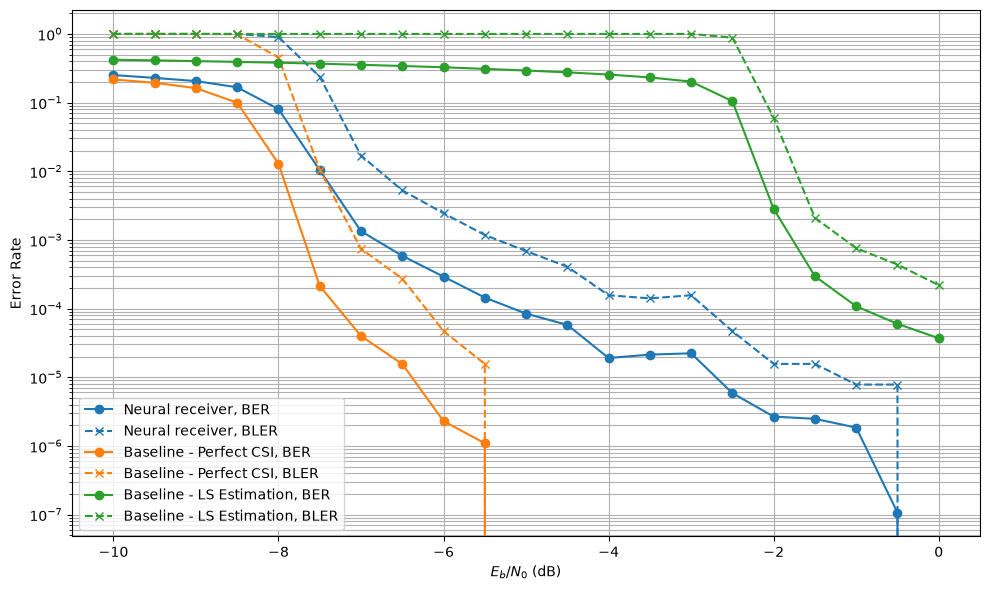

In [8]:
plt.figure(figsize=(10,6))
labels = {"neural_receiver": "Neural receiver", "perfect_csi": "Baseline - Perfect CSI",
          "ls_estimation": "Baseline - LS Estimation"}
for i, system in enumerate(results["system"]):
    system = str(system)
    plt.semilogy(results["ebno_db"], results["ber"][i], "o-", c=f"C{i}",
                 label=f"{labels[system]}, BER")
    plt.semilogy(results["ebno_db"], results["bler"][i], "x--", c=f"C{i}",
                 label=f"{labels[system]}, BLER")

plt.xlabel(r"$E_b/N_0$ (dB)")
plt.ylabel("Error Rate")
plt.grid(which="both")
plt.legend()
plt.tight_layout()
plt.show()

The figure shows the results of the full run, which cell 12 loads from `ML_based_SIMO_receiver_results.npz` without a mode: the dense urban scenario in the uplink at 30 GHz, with a satellite at 600 km and an elevation angle of 80°, without the Doppler shift. The waterfall of the neural receiver lies below the range of its training, [-5, 0.5) dB: its block error rate (BLER) is 1 down to -8.5 dB, 0.24 at -7.5 dB and 0.017 at -7.0 dB, and below 1e-3 from -5.0 dB on. Interpolated linearly in the logarithm of the BLER between the simulated points, the receiver reaches a BLER of 1e-2 at an Eb/N0 of -6.77 dB, about 0.7 dB behind the baseline with perfect CSI (-7.49 dB) and about 5.0 dB ahead of the baseline with LS estimation (-1.73 dB); its distance to perfect CSI grows toward lower BLER, from about 0.5 dB at a BLER of 1e-1 to about 1.7 dB at 1e-3. From -4.0 to -3.0 dB the curve of the receiver flattens, its BLER near 1.5e-4 (20, 18 and 20 block errors in 128 000 blocks each), before it falls again, to one block error in 128 000 at -1.0 and at -0.5 dB and none at 0 dB. These curves come from one training of the receiver on a GPU, which is not reproducible bit for bit, so another training gives other weights and other curves.